# Task 3 – FruitSort Vision Assistant (application integration / tool use)

**FCVG101 – FruitSort Vision Assistant · Task 3**

The assistant links the **Task 1 classical CV engine** (`../task1/src`) and the **Task 2 CNN** (`../task2/src` +
`artifacts/model.pth`). A request in English or Vietnamese goes through

```
user text --> intent.detect_intent  (which tool? which parameters?)
          --> tools.run(mode, images, params) --> Task 1 engine or Task 2 model
          --> ToolResult (figures + metrics + table + warnings) --> shown to the user
```

The GUI is a Streamlit app (`app.py`, it must stay a `.py` file for Streamlit). This notebook runs the same code
without the GUI:

1. load the two engines; 2. the intent router; 3. one request per tool with its visual result;
4. the integration tests T1–T7 of the coursework guide + routing + a headless run of the GUI; 5. how to start the app.

Open the notebook with the working directory set to `task3/`.

In [1]:
import os, re, subprocess, sys, traceback
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TASK3 = Path.cwd()                         # open the notebook from the task3/ folder
sys.path.insert(0, str(TASK3))
from assistant import engines, settings, tools
from assistant.errors import AssistantError
from assistant.intent import MODES, detect_intent

pd.set_option('display.max_colwidth', 90)
print('Task 1 code :', settings.TASK1_DIR.relative_to(settings.COURSEWORK_DIR))
print('Task 2 code :', settings.TASK2_DIR.relative_to(settings.COURSEWORK_DIR))
print('datasets    :', settings.DATASETS_DIR.relative_to(settings.COURSEWORK_DIR))

Task 1 code : task1
Task 2 code : task2
datasets    : datasets


## 1. Loading the engines

`engines.load_task1()` imports `task1/src` under the alias `fcvg_task1` (both tasks call their package `src`);
`load_calibration()` reads `task1/artifacts/calibration.npz`; `load_classifier()` loads `task2/artifacts/model.pth` with
Task 2's own `src.inference.load_model`, so the app uses exactly the preprocessing of training. A missing artifact
raises `AssistantError(message, hint)`, which the GUI shows instead of crashing.

In [2]:
t1 = engines.load_task1()
calib = engines.load_calibration()
clf = engines.load_classifier()
print('Task 1 modules:', [m.__name__ for m in (t1.calibration, t1.filtering, t1.features)])
print(f'Calibration  : {calib.size[0]}x{calib.size[1]}, fx = {calib.K[0, 0]:.1f} px, RMS {calib.rms:.3f} px')
print('Task 2 model :', clf.meta['architecture'], '| classes', clf.classes,
      f"| best epoch {clf.meta['best_epoch']}, val acc {clf.meta['best_val_accuracy']:.1%}")

Task 1 modules: ['fcvg_task1.calibration', 'fcvg_task1.filtering', 'fcvg_task1.features']
Calibration  : 4000x3000, fx = 2754.6 px, RMS 0.458 px
Task 2 model : FruitCNN_3Conv_GAP | classes ['apple', 'banana', 'orange'] | best epoch 54, val acc 94.7%


## 2. Application logic – recognising the request

`assistant/intent.py` is a transparent rule-based router (no internet, no API key):

1. normalise: lower case, strip Vietnamese diacritics (`đ → d`), collapse spaces;
2. score each mode by weighted keyword patterns (technique names such as *canny*, *sift*, *khử méo* weigh 3, generic words 1–2);
3. *classify* + *measure* together become *inspect*; no match or a tie → `mode = None` and the user is asked;
4. extract parameters written in the request (filter, kernel size, SIFT/ORB, ratio, Canny thresholds, distance…).

In [3]:
requests = [
    'phân loại quả này', 'What fruit is this?', 'tìm cạnh bằng Canny', 'find the edges, thresholds 50 150',
    'lọc nhiễu muối tiêu bằng median 7x7', 'apply a low pass FFT filter', 'so khớp ORB giữa hai ảnh, ratio 0.8',
    'detect Harris corners', 'khử méo ảnh này', 'show the camera intrinsic matrix K',
    'đo kích thước quả ở 30 cm', 'how big is this fruit?', 'phân loại và đo kích thước', 'hello there',
]
rows = []
for text in requests:
    it = detect_intent(text)
    rows.append({'request': text, 'mode': it.mode or '(ask the user)', 'reason': it.reason,
                 'parameters': ', '.join(f'{k}={v}' for k, v in it.params.items()) or '-'})
pd.DataFrame(rows)

,request,mode,reason,parameters
0,phân loại quả này,classify,"Matched: 'phan loai', 'loai qua'",-
1,What fruit is this?,classify,Matched: 'what fruit',-
2,tìm cạnh bằng Canny,edges,"Matched: 'canh', 'canny'",-
3,"find the edges, thresholds 50 150",edges,Matched: 'edges',"canny=(50, 150)"
4,lọc nhiễu muối tiêu bằng median 7x7,filter,"Matched: 'loc', 'nhieu', 'median'","filter=median, ksize=7, noise=salt_pepper"
5,apply a low pass FFT filter,filter,"Matched: 'filter', 'fft', 'low pass'",filter=fft_lowpass
6,"so khớp ORB giữa hai ảnh, ratio 0.8",features,"Matched: 'so khop', 'khop', 'orb'","method=ORB, ratio=0.8"
7,detect Harris corners,features,"Matched: 'harris', 'corners'",method=Harris+SIFT
8,khử méo ảnh này,calibrate,"Matched: 'khu meo', 'meo'",-
9,show the camera intrinsic matrix K,calibrate,Matched: 'intrinsic',-


## 3. Tool integration – one request per tool

`ask()` does what the chat box does: detect the intent, merge the parameters from the text, call
`tools.run(mode, images, params, clf, calib)` and show the returned figures, summary, metrics and warnings.

In [4]:
TEST_SPLIT = settings.FRUIT_SPLITS / 'test'
BOARDS = sorted(settings.SAMPLE_DIRS['Checkerboard photos (Task 1A)'].glob('*.jpg'))


def fruit(cls, i=0):
    return tools.read_image_file(sorted((TEST_SPLIT / cls).glob('*.jpg'))[i])


def ask(request, images, max_panels=4, pick=None):
    intent = detect_intent(request)
    res = tools.run(intent.mode, images, intent.params, clf=clf, calib=calib)
    panels = [res.images[i] for i in pick] if pick else res.images[:max_panels]
    fig, axes = plt.subplots(1, len(panels), figsize=(3.8 * len(panels), 3.6), squeeze=False)
    for ax, (caption, im) in zip(axes[0], panels):
        ax.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap='gray' if im.ndim == 2 else None)
        ax.set_title(caption, fontsize=8); ax.axis('off')
    fig.suptitle(f'"{request}" -> {intent.mode} ({intent.reason})', fontsize=9)
    fig.tight_layout(); plt.show()
    print(res.summary.replace('**', ''), f'[{res.elapsed_ms:.0f} ms]')
    for w in res.warnings:
        print('  warning:', w)
    display(pd.DataFrame([res.metrics]).T.rename(columns={0: 'value'}))
    if res.table:
        display(pd.DataFrame(res.table))
    return res

### Classify (Task 2 CNN + Grad-CAM)

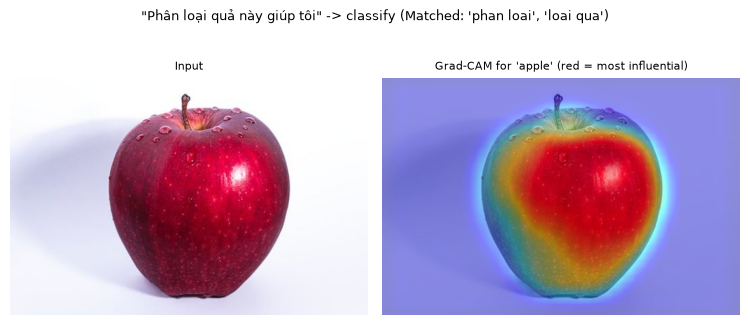

Predicted apple with score 0.991. [340 ms]


,value
predicted class,apple
score (softmax),0.9913
margin to 2nd class,0.9826
model,FruitCNN_3Conv_GAP
input,"128 px, mean/std [0.5, 0.5, 0.5]/[0.5, 0.5, 0.5]"


,class,score
0,apple,0.9913
1,banana,0.0087
2,orange,0.0000


In [5]:
_ = ask('Phân loại quả này giúp tôi', [fruit('apple', 9)])

### Inspect = classify + measure (Task 2 + Task 1)

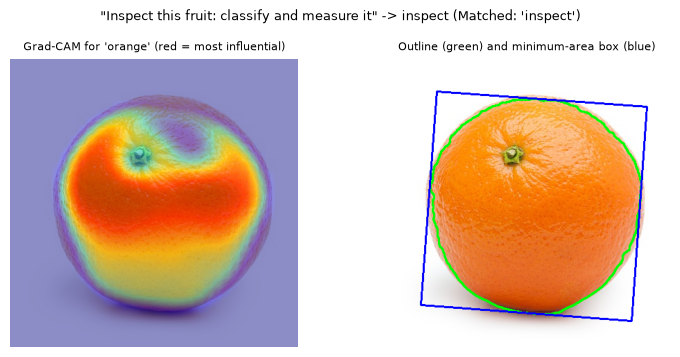

Predicted orange with score 1.000. Fruit outline: equivalent diameter 306 px, 310 x 304 px. [54 ms]


,value
predicted class,orange
score (softmax),1.0
margin to 2nd class,1.0
model,FruitCNN_3Conv_GAP
input,"128 px, mean/std [0.5, 0.5, 0.5]/[0.5, 0.5, 0.5]"
area (px),73407
equivalent diameter (px),305.7
"length x width (px, min-area box)",309.7 x 303.9
touches image border,False
solidity (area / convex hull),0.99


,class,score
0,orange,1.0
1,apple,0.0
2,banana,0.0


In [6]:
_ = ask('Inspect this fruit: classify and measure it', [fruit('orange', 2)])

### Filtering with parameters from the text (Task 1B)

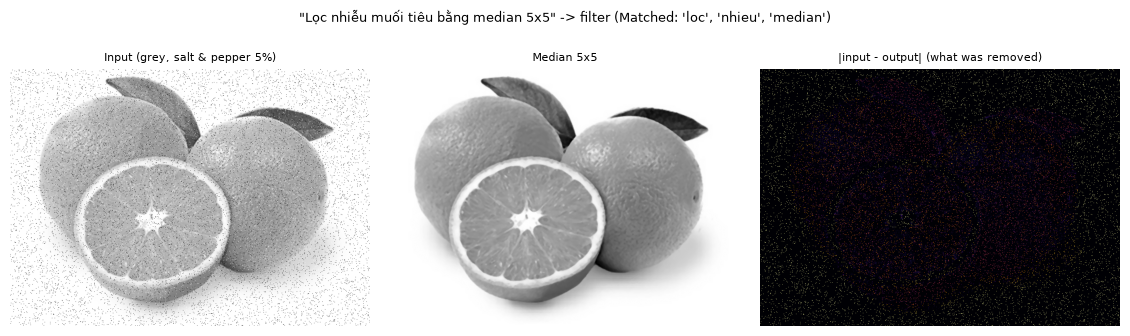

Median filter on salt & pepper 5%: PSNR 17.09 -> 38.44 dB. Best filter for this noise: median 5x5 (38.45 dB). [727 ms]


,value
filter,median
working size,791 x 564
kernel,5 x 5
PSNR noisy -> filtered (dB),17.092 -> 38.44


,image,MSE,PSNR_dB,SSIM
0,noisy input,1270.228,17.092,0.272
1,box 5x5,87.473,28.712,0.715
2,gaussian 5x5,117.043,27.447,0.644
3,median 5x5,9.302,38.445,0.951
4,bilateral 5x5,1187.974,17.383,0.301


In [7]:
_ = ask('Lọc nhiễu muối tiêu bằng median 5x5', [fruit('orange', 12)])

### Frequency-domain filtering (Task 1B)

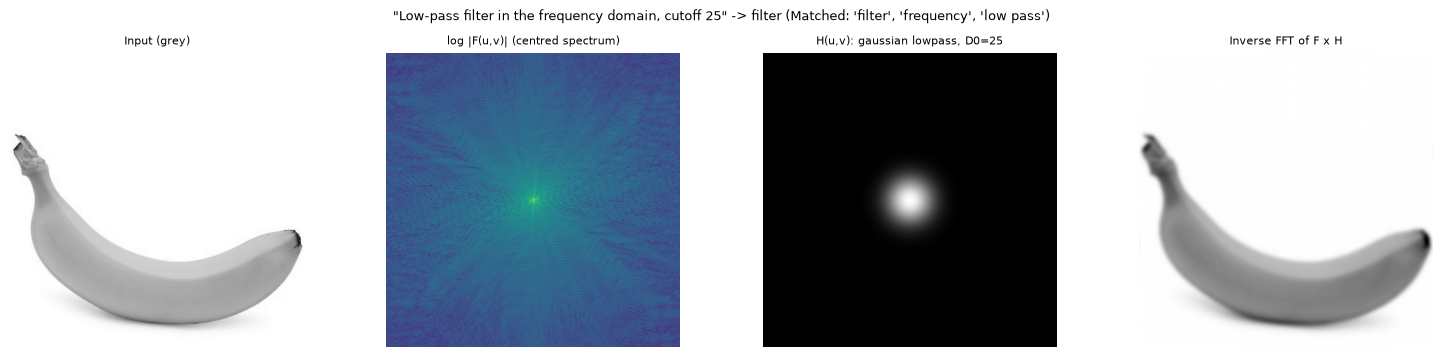

Fourier lowpass (gaussian, D0=25) keeps 99.9% of the spectral energy: fine detail and noise are removed. [67 ms]


,value
filter,fft_lowpass
working size,460 x 460
transfer function,gaussian lowpass
cut-off D0 (frequency px),25
spectral energy kept (%),99.89


In [8]:
_ = ask('Low-pass filter in the frequency domain, cutoff 25', [fruit('banana', 4)])

### Edges and fruit outline (Task 1B)

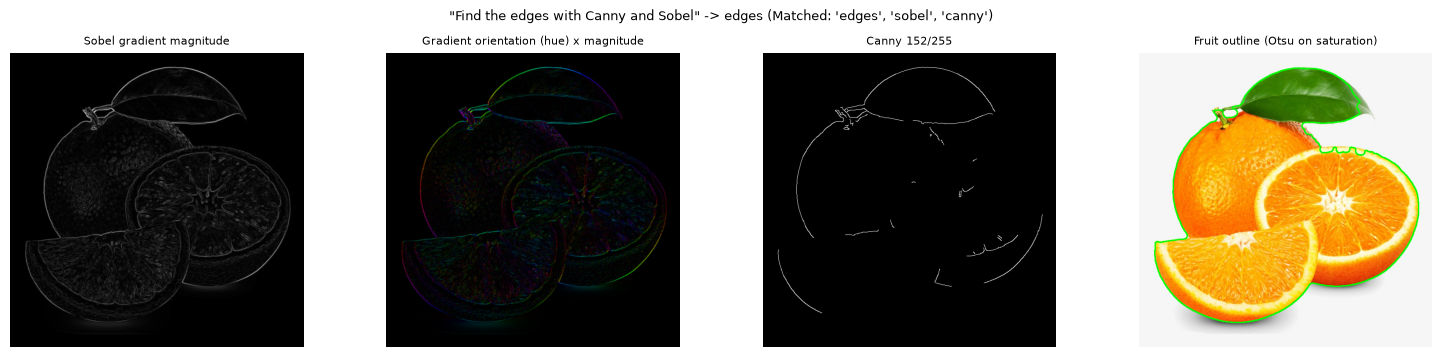

Canny found edges on 0.6% of pixels with thresholds 152/255. Fruit outline circularity 0.492. [68 ms]


,value
working size,650 x 651
Canny thresholds,152 / 255 (auto (median-based))
edge pixels (%),0.6
mean gradient magnitude,28.68
fruit area (% of image),50.6
fruit circularity 4*pi*A/P^2,0.492


In [9]:
_ = ask('Find the edges with Canny and Sobel', [fruit('orange', 0)])

### Keypoints and matching between two views (Task 1C)

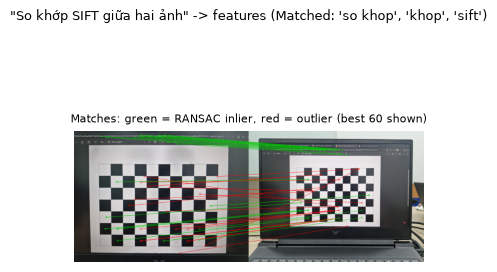

SIFT: 643 / 796 keypoints, 172 matches pass the ratio test 0.75, 81 are RANSAC inliers. [167 ms]


,value
method,SIFT
kp1,643
kp2,796
good_matches,172
ransac_inliers,81
time_ms,130.235
ratio,0.75
pair,two uploaded views


In [10]:
_ = ask('So khớp SIFT giữa hai ảnh', [tools.read_image_file(BOARDS[0]), tools.read_image_file(BOARDS[1])], pick=[-1])

### Undistortion with the Task 1A calibration

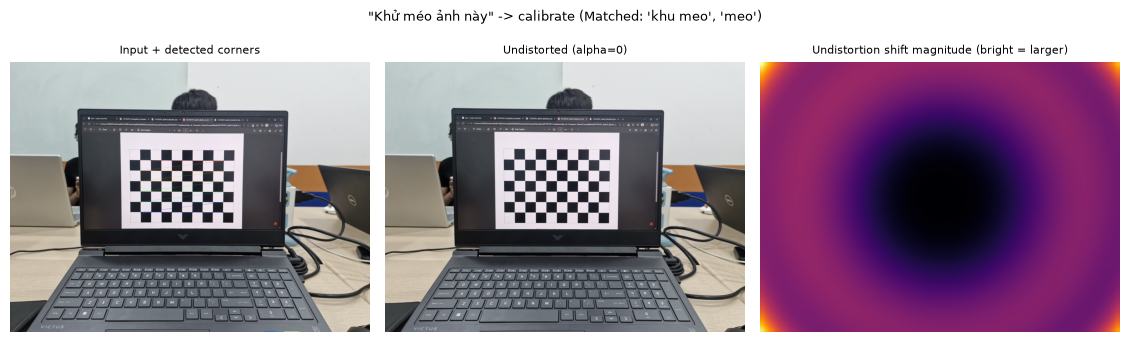

Undistorted with K from Task 1A. Checkerboard rows/columns became straighter: 0.23 px -> 0.09 px RMS deviation from a straight line. [461 ms]


,value
image_size,4000 x 3000
calibrated_at,4000 x 3000
"fx, fy (px, this size)","2754.6, 2754.8"
"cx, cy (px, this size)","1995.5, 1478.8"
"dist (k1,k2,p1,p2,k3)","+0.1438, -0.4284, -0.0003, -0.0003, +0.3594"
calibration RMS (px),0.458
max undistortion shift (px),55.7
horizontal FOV (deg),72.0
board corners,54 found (SB + subpixel)
line straightness before (px RMS),0.23


In [11]:
_ = ask('Khử méo ảnh này', [tools.read_image_file(BOARDS[2])], max_panels=3)

### Unclear request: nothing runs, the user is asked

In [12]:
it = detect_intent('xin chào')
print('mode:', it.mode, '|', it.reason)

mode: None | No known task keyword found.


## 4. Integration tests

Test cases T1–T7 of the coursework guide plus calibration, measurement, routing and a headless run of the Streamlit
GUI (`streamlit.testing.v1.AppTest`). Each `@case` records PASS/FAIL with a short detail; the last cell prints the
summary and fails if any case failed.

In [13]:
RESULTS: list[tuple[str, bool, str]] = []


def case(name):
    def wrap(fn):
        try:
            detail = fn() or ""
            RESULTS.append((name, True, detail))
        except Exception as exc:  # noqa: BLE001
            RESULTS.append((name, False, f"{type(exc).__name__}: {exc}\n{traceback.format_exc(limit=3)}"))
        return fn
    return wrap


def sample(cls: str, i: int = 0) -> Path:
    return sorted((settings.FRUIT_SPLITS / "test" / cls).glob("*.jpg"))[i]


BOARD_DIR = settings.SAMPLE_DIRS["Checkerboard photos (Task 1A)"]
CLF, CAL = clf, calib
APPLE = tools.read_image_file(sample("apple"))

In [14]:
# ---------------------------------------------------------------- T1-T7 (guide section 7.3)
@case("T1 Filtering: output differs, parameters reported")
def _():
    r = tools.run("filter", [APPLE], {"filter": "median", "ksize": 5, "noise": "salt_pepper"})
    out, src = r.images[1][1], r.images[0][1]
    assert out.shape == src.shape and np.abs(out.astype(int) - src).mean() > 1
    assert r.metrics["kernel"] == "5 x 5" and r.table and len(r.table) == 5
    best = max(r.table[1:], key=lambda row: row["PSNR_dB"])
    assert r.table[0]["PSNR_dB"] < best["PSNR_dB"]
    r2 = tools.run("filter", [APPLE], {"filter": "fft_lowpass", "cutoff": 20})
    assert 0 < r2.metrics["spectral energy kept (%)"] <= 100
    return f"{r.summary} | {r2.summary}"

In [15]:
@case("T2 Edges: edge map present, thresholds adjustable")
def _():
    auto = tools.run("edges", [APPLE], {"canny": None})
    manual = tools.run("edges", [APPLE], {"canny": (100, 200)})
    assert manual.metrics["Canny thresholds"].startswith("100 / 200")
    assert auto.metrics["edge pixels (%)"] > 0 and auto.images[2][1].max() == 255
    assert "fruit circularity 4*pi*A/P^2" in auto.metrics
    return auto.summary

In [16]:
@case("T3 Features: two views -> keypoints and matches, no DMatch error")
def _():
    boards = sorted(BOARD_DIR.glob("*.jpg"))[:2]
    pair = [tools.read_image_file(p) for p in boards]
    rows = []
    for method in ("SIFT", "ORB", "Harris+SIFT"):
        r = tools.run("features", pair, {"method": method, "ratio": 0.75})
        assert r.metrics["kp1"] > 0 and r.images[1][1].shape[1] > pair[0].shape[1] * 0  # side-by-side canvas
        rows.append(f"{method}: {r.metrics['good_matches']} good / {r.metrics['ransac_inliers']} inliers")
    single = tools.run("features", [APPLE], {"method": "SIFT"})
    assert "precision" in single.metrics and single.metrics["precision"] > 0.5
    return "; ".join(rows) + f"; synthetic view precision {single.metrics['precision']:.2f}"

In [17]:
@case("T4 Classify: label + score, same preprocessing as Task 2")
def _():
    correct, total = 0, 0
    for cls in CLF.classes:
        for p in sorted((settings.FRUIT_SPLITS / "test" / cls).glob("*.jpg")):
            r = tools.run("classify", [tools.read_image_file(p)], {}, clf=CLF)
            total += 1
            correct += r.metrics["predicted class"] == cls
            assert abs(sum(row["score"] for row in r.table) - 1) < 1e-3
    acc = correct / total
    assert acc > 0.9, acc                     # Task 2 reported 97.4 % on this test split
    return f"test split through the app: {correct}/{total} = {acc:.1%}"

In [18]:
@case("T5 Non-image file -> clear error, no crash")
def _():
    for data, name in [(b"hello, I am a text file", "notes.jpg"), (b"", "empty.png"), (b"%PDF-1.7 ...", "x.pdf")]:
        try:
            tools.decode_image(data, name)
        except AssistantError as exc:
            assert exc.hint
        else:
            raise AssertionError(f"{name} was accepted")
    try:
        tools.run("classify", [], {}, clf=CLF)
    except AssistantError as exc:
        return f"no-image message: {exc.message}"
    raise AssertionError("empty input accepted")

In [19]:
@case("T6 Missing model.pth or K/dist file -> message + how to fix")
def _():
    msgs = []
    for loader in (lambda: engines.load_classifier(Path("does/not/exist/model.pth")),
                   lambda: engines.load_calibration(Path("does/not/exist/calibration.npz"))):
        try:
            loader()
        except AssistantError as exc:
            assert exc.hint
            msgs.append(exc.message)
        else:
            raise AssertionError("missing artifact accepted")
    try:                                                      # tools also cope with a missing engine
        tools.run("classify", [APPLE], {}, clf=None)
    except AssistantError:
        pass
    r = tools.run("measure", [APPLE], {}, calib=None)        # measurement degrades to pixels
    assert any("pixels only" in w for w in r.warnings)
    return " | ".join(msgs)

In [20]:
@case("T7 Clean machine: no personal absolute paths, env overrides work")
def _():
    pattern = re.compile(r"(?<![A-Za-z])[A-Za-z]:[\\/]|[\\/]Users[\\/]|venvs")
    offenders = [str(p.relative_to(TASK3)) for p in TASK3.rglob("*.py")
                 if "tests" not in p.parts and pattern.search(p.read_text(encoding="utf-8"))]
    assert not offenders, offenders
    code = ("import sys; sys.path.insert(0, r'%s'); from assistant import settings; print(settings.MODEL_FILE)" % TASK3)
    env = {**os.environ, "FCVG_MODEL_FILE": str(TASK3 / "elsewhere" / "m.pth")}
    out = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True, env=env, cwd=Path.home())
    assert out.stdout.strip().endswith(str(Path("elsewhere") / "m.pth")), out.stdout + out.stderr
    return "paths are relative to task3/; FCVG_* variables override them"

In [21]:
# ---------------------------------------------------------------- other tools
@case("Calibrate: undistort a board photo, straighter lines")
def _():
    board = tools.read_image_file(sorted(BOARD_DIR.glob("*.jpg"))[0])
    r = tools.run("calibrate", [board], {"alpha": 0.0}, calib=CAL)
    assert r.metrics["line straightness after (px RMS)"] < r.metrics["line straightness before (px RMS)"]
    small = tools.resize_max_side(board, 1000)[0]             # resized photo -> K rescaled
    r2 = tools.run("calibrate", [small], {}, calib=CAL)
    assert "fx, fy (px, this size)" in r2.metrics
    try:                                                      # different aspect ratio -> refused
        tools.run("calibrate", [APPLE[:, : APPLE.shape[0]]], {}, calib=CAL)
    except AssistantError:
        pass
    else:
        raise AssertionError("square image accepted for a 4:3 calibration")
    return r.summary

In [22]:
@case("Calibrate: >= 3 board photos -> new calibration")
def _():
    boards = [tools.resize_max_side(tools.read_image_file(p), 1600)[0] for p in sorted(BOARD_DIR.glob("*.jpg"))[:6]]
    r = tools.run("calibrate", boards, {}, calib=CAL)
    assert r.metrics["RMS reprojection error (px)"] < 2
    return r.summary + f" fx vs stored K: {r.metrics.get('fx vs stored K (%)')} %"

In [23]:
@case("Measure + Inspect: size in px, mm when distance given")
def _():
    r = tools.run("measure", [APPLE], {"distance_mm": 300}, calib=CAL)
    assert r.metrics["equivalent diameter (px)"] > 10
    i = tools.run("inspect", [APPLE], {"distance_mm": 300}, clf=CLF, calib=CAL)
    assert i.metrics["predicted class"] == "apple"
    return r.summary

In [24]:
# ---------------------------------------------------------------- intent routing (rubric 3.1)
ROUTING = [
    ("phân loại quả này", "classify"), ("What fruit is this?", "classify"), ("đây là quả gì vậy", "classify"),
    ("tìm cạnh bằng Canny", "edges"), ("show me the Sobel gradients", "edges"), ("vẽ đường viền quả", "edges"),
    ("lọc nhiễu muối tiêu bằng median 7x7", "filter"), ("apply a Fourier low-pass filter", "filter"),
    ("làm mờ ảnh", "filter"), ("so khớp SIFT giữa hai ảnh", "features"), ("detect ORB keypoints", "features"),
    ("khử méo ảnh này", "calibrate"), ("undistort with the camera matrix", "calibrate"),
    ("đo kích thước quả ở 30 cm", "measure"), ("how big is this fruit?", "measure"),
    ("phân loại và đo kích thước", "inspect"), ("inspect this fruit", "inspect"),
    ("xin chào", None), ("", None),
]

In [25]:
@case("Intent router: requests -> correct mode")
def _():
    wrong = [(t, want, detect_intent(t).mode) for t, want in ROUTING if detect_intent(t).mode != want]
    assert not wrong, wrong
    p = detect_intent("lọc median 7x7 với nhiễu muối tiêu").params
    assert p["filter"] == "median" and p["ksize"] == 7 and p["noise"] == "salt_pepper", p
    assert detect_intent("đo ở 30 cm").params["distance_mm"] == 300
    assert detect_intent("match with ORB ratio 0.8").params == {"method": "ORB", "ratio": 0.8}
    return f"{len(ROUTING)} requests routed correctly"

In [26]:
# ---------------------------------------------------------------- headless UI (Streamlit AppTest)
@case("UI: chat request runs the tool end-to-end")
def _():
    from streamlit.testing.v1 import AppTest
    os.chdir(TASK3)
    at = AppTest.from_file(str(TASK3 / "app.py"), default_timeout=120)
    at.run()
    assert not at.exception, at.exception
    at.radio(key="source").set_value("Sample images").run()
    shown = []
    for text, expect in [("phân loại quả này", "Predicted"), ("tìm cạnh bằng Canny", "Canny"),
                         ("lọc median 5x5", "Median"), ("so khớp SIFT", "SIFT"), ("xin chào", "could not tell")]:
        at.chat_input[0].set_value(text).run()
        assert not at.exception, at.exception
        page = " ".join(m.value for m in at.markdown) + " ".join(e.value for e in at.error)
        assert expect in page, (text, expect)
        shown.append(text)
    at.button(key="quick_inspect").run()
    assert not at.exception and "Predicted" in " ".join(m.value for m in at.markdown)
    return f"{len(shown)} chat requests + 1 quick action rendered without exceptions"

2026-11-18 23:12:58.625 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [27]:
summary = pd.DataFrame(RESULTS, columns=['case', 'passed', 'detail'])
display(summary)
print(f"{summary.passed.sum()}/{len(summary)} passed")
assert summary.passed.all(), summary[~summary.passed]

,case,passed,detail
0,"T1 Filtering: output differs, parameters reported",True,Median filter on salt & pepper 5%: PSNR 17.93 -> 27.22 dB. Best filter for this noise:...
1,"T2 Edges: edge map present, thresholds adjustable",True,Canny found edges on 7.08% of pixels with thresholds 64/129. Fruit outline circularity...
2,"T3 Features: two views -> keypoints and matches, no DMatch error",True,SIFT: 172 good / 81 inliers; ORB: 227 good / 29 inliers; Harris+SIFT: 9 good / 7 inlie...
3,"T4 Classify: label + score, same preprocessing as Task 2",True,test split through the app: 37/38 = 97.4%
4,"T5 Non-image file -> clear error, no crash",True,"no-image message: Mode 'classify' needs 1 image(s), got 0."
5,T6 Missing model.pth or K/dist file -> message + how to fix,True,Trained model artifact not found: does\not\exist\model.pth | Calibration file not foun...
6,"T7 Clean machine: no personal absolute paths, env overrides work",True,paths are relative to task3/; FCVG_* variables override them
7,"Calibrate: undistort a board photo, straighter lines",True,Undistorted with K from Task 1A. Checkerboard rows/columns became straighter: 0.95 px ...
8,Calibrate: >= 3 board photos -> new calibration,True,New calibration from 6 checkerboard views: RMS reprojection error 0.137 px. fx vs stor...
9,"Measure + Inspect: size in px, mm when distance given",True,"Fruit outline: equivalent diameter 328 px, 392 x 349 px."


12/12 passed


## 5. Starting the GUI

```powershell
cd task3
streamlit run app.py        # opens http://localhost:8501
```

Upload a photo (or choose *Sample images*), type a request such as *"phân loại quả này"*, *"tìm cạnh bằng Canny"*,
*"so khớp ORB"* or *"đo kích thước quả ở 30 cm"*, or press a quick-action button. The sidebar shows whether the
engines and artifacts are loaded and lets you force a mode or change parameters. If the folders are arranged
differently, set `FCVG_TASK1_DIR`, `FCVG_TASK2_DIR`, `FCVG_DATASETS_DIR`, `FCVG_CALIBRATION_FILE` or `FCVG_MODEL_FILE`.